In [37]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
from typing import List, Dict, Optional
import requests
import pandas as pd
import time
import json
from time import sleep


In [38]:
def fetch_wikipedia_nyt100() -> pd.DataFrame:
    url = "https://en.wikipedia.org/wiki/NYT%27s_100_Best_Movies_of_the_21st_Century"
    headers = {
        "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
                      "AppleWebKit/537.36 (KHTML, like Gecko) "
                      "Chrome/117.0.0.0 Safari/537.36"
    }
    
    resp = requests.get(url, headers=headers)
    resp.raise_for_status()
    dfs = pd.read_html(resp.text)

    # Inspect which table is correct. Let's assume the first relevant one is dfs[0]
    df = dfs[0]
    # Standardize column names
    df = df.rename(columns={
        "No.": "rank",
        "Title": "title",
        "Director": "director",
        "Country": "country",
        "Year": "year"
    })
    return df

In [39]:
df_basic =fetch_wikipedia_nyt100()

/var/folders/ns/rykfnvcd2m5290k7kpxhz2_m0000gn/T/ipykernel_40859/3548221592.py:11: FutureWarning:

Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.



In [40]:
df_basic.tail()

,rank,title,director,country,year
5,6,No Country for Old Men,Joel Coen and Ethan Coen,United States,2007
6,7,Eternal Sunshine of the Spotless Mind,Michel Gondry,United States,2004
7,8,Get Out,Jordan Peele,United States,2017
8,9,Spirited Away,Hayao Miyazaki,Japan,2001
9,10,The Social Network,David Fincher,United States,2010


In [41]:
# Your provided list of 100 titles (I'll store them in a Python list)
all_titles = [
    "Parasite",
    "Mulholland Drive",
    "No Country for Old Men",
    "There Will Be Blood",
    "Interstellar",
    "The Dark Knight",
    "Mad Max: Fury Road",
    "Spirited Away",
    "Eternal Sunshine of the Spotless Mind",
    "The Social Network",
    "Inglourious Basterds",
    "In the Mood for Love",
    "Everything Everywhere All at Once",
    "The LotR: The Fellowship of the Ring",
    "The LotR: The Return of the King",
    "La La Land",
    "Get Out",
    "Moonlight",
    "Whiplash",
    "Arrival",
    "Children of Men",
    "The Grand Budapest Hotel",
    "Oppenheimer",
    "Inception",
    "The Departed",
    "Portrait of a Lady on Fire",
    "Dune: Part Two",
    "The Royal Tenenbaums",
    "Once Upon a Time… in Hollywood",
    "Brokeback Mountain",
    "Before Sunset",
    "Lost in Translation",
    "Gladiator",
    "Spider-Man: Into the Spider-Verse",
    "Aftersun",
    "Lady Bird",
    "City of God",
    "Call Me by Your Name",
    "Pan’s Labyrinth",
    "Oldboy",
    "Zodiac",
    "Little Miss Sunshine",
    "The LotR: The Two Towers",
    "WALL·E",
    "Phantom Thread",
    "Amélie",
    "Past Lives",
    "Kill Bill: Vol. 1",
    "Memories of Murder",
    "Pride & Prejudice",
    "Almost Famous",
    "Sinners",
    "Superbad",
    "The Wolf of Wall Street",
    "Y tu mamá también",
    "The Zone of Interest",
    "Ocean’s Eleven",
    "Ratatouille",
    "Django Unchained",
    "Little Women",
    "Memento",
    "Hereditary",
    "Blade Runner 2049",
    "Her",
    "Fantastic Mr. Fox",
    "O Brother, Where Art Thou?",
    "The Handmaiden",
    "Tár",
    "Yi Yi",
    "The Florida Project",
    "The Tree of Life",
    "Uncut Gems",
    "Spotlight",
    "Black Swan",
    "Boyhood",
    "The Worst Person in the World",
    "The Prestige",
    "Michael Clayton",
    "Gone Girl",
    "Anatomy of a Fall",
    "Crouching Tiger, Hidden Dragon",
    "Mean Girls",
    "Perfect Days",
    "Barbie",
    "Up",
    "Dune: Part One",
    "The Master",
    "Top Gun: Maverick",
    "Drive My Car",
    "Bridesmaids",
    "Knives Out",
    "The Incredibles",
    "Killers of the Flower Moon",
    "Moneyball",
    "Inside Llewyn Davis",
    "Howl’s Moving Castle",
    "The Lighthouse",
    "The Holdovers",
    "Midsommar",
    "Avengers: Endgame"
]



In [42]:


# Make sure your list is exactly 100 long
print(len(all_titles))   # should print 100

df_basic = pd.DataFrame({
    "rank": list(range(1, 101)),
    "title": all_titles
})

print(df_basic.head(15))
print(df_basic.tail(5))


100
    rank                                  title
0      1                               Parasite
1      2                       Mulholland Drive
2      3                 No Country for Old Men
3      4                    There Will Be Blood
4      5                           Interstellar
5      6                        The Dark Knight
6      7                     Mad Max: Fury Road
7      8                          Spirited Away
8      9  Eternal Sunshine of the Spotless Mind
9     10                     The Social Network
10    11                   Inglourious Basterds
11    12                   In the Mood for Love
12    13      Everything Everywhere All at Once
13    14   The LotR: The Fellowship of the Ring
14    15       The LotR: The Return of the King
    rank                 title
95    96  Howl’s Moving Castle
96    97        The Lighthouse
97    98         The Holdovers
98    99             Midsommar
99   100     Avengers: Endgame


In [43]:


def enrich_with_omdb(df: pd.DataFrame, api_key: str, sleep_time: float = 0.2) -> pd.DataFrame:
    """
    Given a DataFrame with at least columns: rank, title
    Query OMDb API for each title and add all metadata.
    """

    # columns you want from OMDb (flat fields)
    omdb_fields = [
        "Title", "Year", "Rated", "Released", "Runtime", "Genre", 
        "Director", "Writer", "Actors", "Plot", "Language", "Country", 
        "Awards", "Poster", "Metascore", "imdbRating", "imdbVotes", 
        "imdbID", "Type", "DVD", "BoxOffice", "Production", "Website"
    ]

    # Add columns if missing
    for col in omdb_fields:
        if col not in df.columns:
            df[col] = None

    # Ratings will be handled separately (dynamic columns)
    
    for idx, row in df.iterrows():
        title = row["title"]
        params = {
            "apikey": api_key,
            "t": title,
            "type": "movie"
        }

        try:
            r = requests.get("http://www.omdbapi.com/", params=params)
            data = r.json()

            if data.get("Response") == "True":
                # fill in the flat fields
                for field in omdb_fields:
                    if field in data:
                        df.at[idx, field] = data[field]

                # handle Ratings list
                if "Ratings" in data:
                    for rating in data["Ratings"]:
                        src = rating["Source"].replace(" ", "_")
                        colname = f"rating_{src}"
                        if colname not in df.columns:
                            df[colname] = None
                        df.at[idx, colname] = rating["Value"]

            else:
                print(f"❌ Skipped Rank {row['rank']} – {title} (not found)")

        except Exception as e:
            print(f"⚠️ Error for Rank {row['rank']} – {title}: {e}")

        time.sleep(sleep_time)  # be polite to the API

    return df


In [44]:
api_key = "26c5456a"

df_enriched = enrich_with_omdb(df_basic.copy(), api_key)

# Preview
print(df_enriched.head(3).T)   # transpose for readability


⚠️ Error for Rank 9 – Eternal Sunshine of the Spotless Mind: Expecting value: line 1 column 1 (char 0)
❌ Skipped Rank 14 – The LotR: The Fellowship of the Ring (not found)
❌ Skipped Rank 15 – The LotR: The Return of the King (not found)
⚠️ Error for Rank 17 – Get Out: Expecting value: line 1 column 1 (char 0)
❌ Skipped Rank 29 – Once Upon a Time… in Hollywood (not found)
❌ Skipped Rank 43 – The LotR: The Two Towers (not found)
⚠️ Error for Rank 92 – The Incredibles: Expecting value: line 1 column 1 (char 0)
                                                                                0  \
rank                                                                            1   
title                                                                    Parasite   
Title                                                                    Parasite   
Year                                                                         2019   
Rated                                                         

In [61]:
df_enriched

,rank,title,Title,Year,Rated,Released,Runtime,Genre,Director,Writer,...,rating_Internet_Movie_Database,rating_Rotten_Tomatoes,rating_Metacritic,Response,BoxOffice_clean,Runtime_clean,PrimaryGenre,rotten_clean,imdb_clean,metacritic_clean
0,1,Parasite,Parasite,2019,R,08 Nov 2019,132 min,"Drama, Thriller",Bong Joon Ho,"Bong Joon Ho, Han Jin-won",...,8.5/10,99%,97/100,None,53847897.0,132.0,Drama,99.0,8.5,97.0
1,2,Mulholland Drive,Mulholland Drive,2001,R,19 Oct 2001,147 min,"Drama, Mystery, Thriller",David Lynch,David Lynch,...,7.9/10,84%,87/100,None,7220243.0,147.0,Drama,84.0,7.9,87.0
2,3,No Country for Old Men,No Country for Old Men,2007,R,21 Nov 2007,122 min,"Crime, Drama, Thriller","Ethan Coen, Joel Coen","Joel Coen, Ethan Coen, Cormac McCarthy",...,8.2/10,93%,92/100,None,74283625.0,122.0,Crime,93.0,8.2,92.0
3,4,There Will Be Blood,There Will Be Blood,2007,R,25 Jan 2008,158 min,Drama,Paul Thomas Anderson,"Paul Thomas Anderson, Upton Sinclair",...,8.2/10,91%,93/100,None,40222514.0,158.0,Drama,91.0,8.2,93.0
4,5,Interstellar,Interstellar,2014,PG-13,07 Nov 2014,169 min,"Adventure, Drama, Sci-Fi",Christopher Nolan,"Jonathan Nolan, Christopher Nolan",...,8.7/10,73%,74/100,None,203227580.0,169.0,Adventure,73.0,8.7,74.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,Howl’s Moving Castle,Howl's Moving Castle,2004,PG,17 Jun 2005,119 min,"Animation, Adventure, Family",Hayao Miyazaki,"Hayao Miyazaki, Diana Wynne Jones",...,8.2/10,88%,82/100,None,10352604.0,119.0,Animation,88.0,8.2,82.0
96,97,The Lighthouse,The Lighthouse,2019,R,01 Nov 2019,109 min,"Drama, Fantasy, Horror",Robert Eggers,"Robert Eggers, Max Eggers",...,7.4/10,90%,83/100,None,10867104.0,109.0,Drama,90.0,7.4,83.0
97,98,The Holdovers,The Holdovers,2023,R,10 Nov 2023,133 min,"Comedy, Drama",Alexander Payne,David Hemingson,...,7.9/10,97%,82/100,None,20355375.0,133.0,Comedy,97.0,7.9,82.0
98,99,Midsommar,Midsommar,2019,R,03 Jul 2019,148 min,"Drama, Horror, Mystery",Ari Aster,Ari Aster,...,7.1/10,83%,72/100,None,27426361.0,148.0,Drama,83.0,7.0,72.0


In [46]:
def patch_rows_with_imdbid(df, api_key, id_map, sleep_time: float = 0.2):
    """
    Patch specific rows in-place using IMDb IDs.
    id_map = {rank: imdbID}
    """
    for rank, imdb_id in id_map.items():
        try:
            params = {"apikey": api_key, "i": imdb_id}
            r = requests.get("http://www.omdbapi.com/", params=params)
            data = r.json()

            if data.get("Response") != "True":
                print(f"❌ IMDbID fetch failed for Rank {rank} ({imdb_id})")
                continue

            # Update every key returned by OMDb directly into that row
            for key, value in data.items():
                if key == "Ratings":  # handle ratings separately
                    for rating in value:
                        src = rating["Source"].replace(" ", "_")
                        colname = f"rating_{src}"
                        if colname not in df.columns:
                            df[colname] = None
                        df.loc[df["rank"] == rank, colname] = rating["Value"]
                else:
                    if key not in df.columns:
                        df[key] = None
                    df.loc[df["rank"] == rank, key] = value

            print(f"✅ Patched Rank {rank} with IMDbID {imdb_id}")

        except Exception as e:
            print(f"⚠️ Error patching Rank {rank}: {e}")

        time.sleep(sleep_time)


In [47]:
# Manual mapping for tricky titles
manual_ids = {
    14: "tt0120737",  # The Fellowship of the Ring
    15: "tt0167260",  # The Return of the King
    29: "tt7131622",  # Once Upon a Time in Hollywood
    43: "tt0167261",  # The Two Towers
}

patch_rows_with_imdbid(df_enriched, api_key, manual_ids)

✅ Patched Rank 14 with IMDbID tt0120737
✅ Patched Rank 15 with IMDbID tt0167260
✅ Patched Rank 29 with IMDbID tt7131622
✅ Patched Rank 43 with IMDbID tt0167261


In [48]:
df_enriched

,rank,title,Title,Year,Rated,Released,Runtime,Genre,Director,Writer,...,imdbID,Type,DVD,BoxOffice,Production,Website,rating_Internet_Movie_Database,rating_Rotten_Tomatoes,rating_Metacritic,Response
0,1,Parasite,Parasite,2019,R,08 Nov 2019,132 min,"Drama, Thriller",Bong Joon Ho,"Bong Joon Ho, Han Jin-won",...,tt6751668,movie,N/A,"$53,847,897",N/A,N/A,8.5/10,99%,97/100,None
1,2,Mulholland Drive,Mulholland Drive,2001,R,19 Oct 2001,147 min,"Drama, Mystery, Thriller",David Lynch,David Lynch,...,tt0166924,movie,N/A,"$7,220,243",N/A,N/A,7.9/10,84%,87/100,None
2,3,No Country for Old Men,No Country for Old Men,2007,R,21 Nov 2007,122 min,"Crime, Drama, Thriller","Ethan Coen, Joel Coen","Joel Coen, Ethan Coen, Cormac McCarthy",...,tt0477348,movie,N/A,"$74,283,625",N/A,N/A,8.2/10,93%,92/100,None
3,4,There Will Be Blood,There Will Be Blood,2007,R,25 Jan 2008,158 min,Drama,Paul Thomas Anderson,"Paul Thomas Anderson, Upton Sinclair",...,tt0469494,movie,N/A,"$40,222,514",N/A,N/A,8.2/10,91%,93/100,None
4,5,Interstellar,Interstellar,2014,PG-13,07 Nov 2014,169 min,"Adventure, Drama, Sci-Fi",Christopher Nolan,"Jonathan Nolan, Christopher Nolan",...,tt0816692,movie,N/A,"$203,227,580",N/A,N/A,8.7/10,73%,74/100,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,Howl’s Moving Castle,Howl's Moving Castle,2004,PG,17 Jun 2005,119 min,"Animation, Adventure, Family",Hayao Miyazaki,"Hayao Miyazaki, Diana Wynne Jones",...,tt0347149,movie,N/A,"$10,352,604",N/A,N/A,8.2/10,88%,82/100,None
96,97,The Lighthouse,The Lighthouse,2019,R,01 Nov 2019,109 min,"Drama, Fantasy, Horror",Robert Eggers,"Robert Eggers, Max Eggers",...,tt7984734,movie,N/A,"$10,867,104",N/A,N/A,7.4/10,90%,83/100,None
97,98,The Holdovers,The Holdovers,2023,R,10 Nov 2023,133 min,"Comedy, Drama",Alexander Payne,David Hemingson,...,tt14849194,movie,N/A,"$20,355,375",N/A,N/A,7.9/10,97%,82/100,None
98,99,Midsommar,Midsommar,2019,R,03 Jul 2019,148 min,"Drama, Horror, Mystery",Ari Aster,Ari Aster,...,tt8772262,movie,N/A,"$27,426,361",N/A,N/A,7.1/10,83%,72/100,None


In [49]:
print(df_enriched[df_enriched["rank"].isin([3, 14, 29, 28, 43])])


    rank                                 title  \
2      3                No Country for Old Men   
13    14  The LotR: The Fellowship of the Ring   
27    28                  The Royal Tenenbaums   
28    29        Once Upon a Time… in Hollywood   
42    43              The LotR: The Two Towers   

                                                Title  Year  Rated  \
2                              No Country for Old Men  2007      R   
13  The Lord of the Rings: The Fellowship of the Ring  2001  PG-13   
27                               The Royal Tenenbaums  2001      R   
28                   Once Upon a Time... in Hollywood  2019      R   
42              The Lord of the Rings: The Two Towers  2002  PG-13   

       Released  Runtime                      Genre               Director  \
2   21 Nov 2007  122 min     Crime, Drama, Thriller  Ethan Coen, Joel Coen   
13  19 Dec 2001  178 min  Adventure, Drama, Fantasy          Peter Jackson   
27  04 Jan 2002  110 min              Comedy

In [50]:
df_enriched.to_csv("nyt_100_movies.csv", index=False)


In [51]:
#simple charts to understand patternswhats

In [52]:
#lets look into runtimes by genre--I have a feeling that that will be a thing 


In [53]:
import plotly.express as px
import pandas as pd

# assume df_enriched is your dataframe
# clean the BoxOffice and Runtime columns and extract first genre
df_enriched = df_enriched.copy()
df_enriched["BoxOffice_clean"] = (
    df_enriched["BoxOffice"]
    .replace('[\$,]', '', regex=True)
    .astype(float)
)

df_enriched["Runtime_clean"] = (
    df_enriched["Runtime"]
    .str.replace(' min', '', regex=False)
    .astype(float)
)

# take only the first genre before the comma
df_enriched["PrimaryGenre"] = df_enriched["Genre"].str.split(',').str[0].str.strip()

# create scatter plot
fig = px.scatter(
    df_enriched,
    x="BoxOffice_clean",
    y="Runtime_clean",
    color="PrimaryGenre",
    hover_data=["Title", "Genre", "BoxOffice", "Runtime"],
    title="Box Office vs Runtime by Primary Genre",
    labels={"BoxOffice_clean": "Box Office ($)", "Runtime_clean": "Runtime (minutes)"}
)

fig.show()


<>:9: SyntaxWarning:

invalid escape sequence '\$'

<>:9: SyntaxWarning:

invalid escape sequence '\$'

/var/folders/ns/rykfnvcd2m5290k7kpxhz2_m0000gn/T/ipykernel_40859/31870605.py:9: SyntaxWarning:

invalid escape sequence '\$'



In [54]:

df_enriched["BoxOffice_clean"] = (
    df_enriched["BoxOffice"]
    .replace('[\$,]', '', regex=True)
    .astype(float)
)

df_enriched["rotten_clean"] = (
    df_enriched["rating_Rotten_Tomatoes"]
    .replace('[%]', '', regex=True)
    .astype(float)
)

# take only the first genre before the comma
df_enriched["PrimaryGenre"] = df_enriched["Genre"].str.split(',').str[0].str.strip()

# create scatter plot
fig = px.scatter(
    df_enriched,
    x="BoxOffice_clean",
    y="rotten_clean",
    color="PrimaryGenre",
    hover_data=["Title", "Genre", "BoxOffice", "Runtime"],
    title="Box Office vs Runtime by Primary Genre",
    labels={"BoxOffice_clean": "Box Office ($)", "Runtime_clean": "Runtime (minutes)"}
)

fig.show()


<>:3: SyntaxWarning:

invalid escape sequence '\$'

<>:3: SyntaxWarning:

invalid escape sequence '\$'

/var/folders/ns/rykfnvcd2m5290k7kpxhz2_m0000gn/T/ipykernel_40859/3574231152.py:3: SyntaxWarning:

invalid escape sequence '\$'



In [55]:

df_enriched["imdb_clean"] = (
    df_enriched["rating_Internet_Movie_Database"]
    .replace('[/10]', '', regex=True)
    .astype(float)
)

# take only the first genre before the comma
df_enriched["PrimaryGenre"] = df_enriched["Genre"].str.split(',').str[0].str.strip()

# create scatter plot
fig = px.scatter(
    df_enriched,
    x="imdb_clean",
    y="rotten_clean",
    color="PrimaryGenre",
    hover_data=["Title", "Genre", "BoxOffice", "Runtime"],
    title="imdb vs rotten tomato by Primary Genre",
    labels={"imdb_clean": "IMDB", "rotten_clean": "Rotten tomatoes"}
)

fig.show()


In [56]:

# Clean Metacritic ratings like '97/100'
df_enriched["metacritic_clean"] = (
    df_enriched["rating_Metacritic"]
    .astype(str)                      # ensure string
    .str.extract(r"(\d+)")            # extract the numeric part before '/'
    .astype(float)
)



# create scatter plot
fig = px.scatter(
    df_enriched,
    x="imdb_clean",
    y="metacritic_clean",
    color="PrimaryGenre",
    hover_data=["Title", "Genre", "BoxOffice", "Runtime"],
    title="imdb vs rotten tomato by Primary Genre",
    labels={"imdb_clean": "IMDB", "metacritic_clean": "Metacritic"}
)

fig.show()


In [57]:
# create scatter plot
fig = px.scatter(
    df_enriched,
    x="BoxOffice_clean",
    y="metacritic_clean",
    color="PrimaryGenre",
    hover_data=["Title", "Genre", "BoxOffice", "Runtime"],
    title="Box Office vs MetaCritic by Primary Genre",
    labels={"BoxOffice_clean": "Box Office($)", "metacritic_clean": "Metacritic(/100)"}
)

fig.show()

In [58]:
#lol I forgot the nyt thingy was literally ranks so lets do one w boxoffice vs that too
# create scatter plot
fig = px.scatter(
    df_enriched,
    x="BoxOffice_clean",
    y="rank",
    color="PrimaryGenre",
    hover_data=["Title", "Genre", "BoxOffice", "Runtime"],
    title="Box Office vs MetaCritic by Primary Genre",
    labels={"BoxOffice_clean": "Box Office($)", "rank": "Rank(/100)"}
)

fig.show()

In [59]:
#but films with multiple genre is kinda more cool, how can I add that nuance?
# small multiples by genre with representation in everything instead of just the first?

In [62]:
# image exploration, metadata exploration, 

In [63]:

with open("Spirited.Away.2001.720p.BluRay.X264-AMIABLE (v2).ass", "r", encoding="utf-8") as f:
    text = f.read()

dialogue_lines = [line for line in text.splitlines() if line.startswith("Dialogue:")]

data = []
for line in dialogue_lines:
    # Split by commas, but only the first 9 commas (the 10th part is text)
    parts = line.split(",", 9)
    if len(parts) >= 10:
        start_time = parts[1].strip()
        end_time = parts[2].strip()
        dialogue = parts[9].strip()
        # Remove any inline formatting like {\i1} or {\fad(300,300)}
        dialogue = re.sub(r"\{.*?\}", "", dialogue)
        data.append({"start_time": start_time, "end_time": end_time, "dialogue": dialogue})

spiritedAway_transcript = pd.DataFrame(data)
print(spiritedAway_transcript.head())


   start_time    end_time                                 dialogue
0  0:00:13.34  0:00:19.72  Good luck, Chihiro \NHope we meet again
1  0:00:16.10  0:00:19.10                        Chihiro? Chihiro!
2  0:00:19.10  0:00:20.56                      We're almost there.
3  0:00:23.52  0:00:25.60    This really is the middle of nowhere.
4  0:00:25.60  0:00:28.57      I'll have to shop in the next town.


In [65]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
nltk.download('vader_lexicon')

sid = SentimentIntensityAnalyzer()
spiritedAway_transcript["sentiment"] = spiritedAway_transcript["dialogue"].apply(lambda x: sid.polarity_scores(x)["compound"])


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/katherine/nltk_data...


In [66]:
spiritedAway_transcript["sentiment_smooth"] = spiritedAway_transcript["sentiment"].rolling(window=20, min_periods=1).mean()


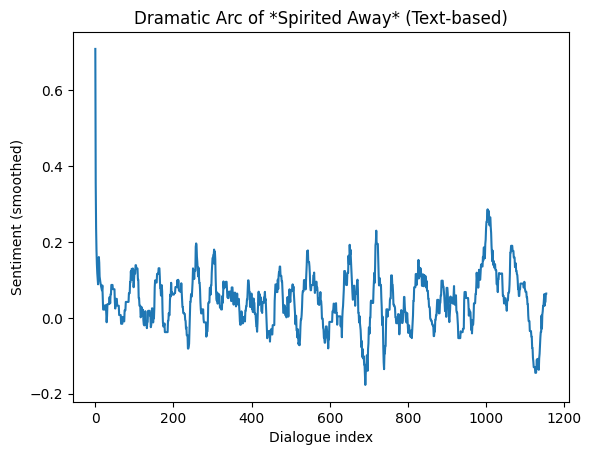

In [67]:
import matplotlib.pyplot as plt

plt.plot(spiritedAway_transcript["sentiment_smooth"])
plt.title("Dramatic Arc of *Spirited Away* (Text-based)")
plt.xlabel("Dialogue index")
plt.ylabel("Sentiment (smoothed)")
plt.show()


In [68]:
spiritedAway_transcript.columns

Index(['start_time', 'end_time', 'dialogue', 'sentiment', 'sentiment_smooth'], dtype='object')

In [69]:
!pip install NRCLex
from nrclex import NRCLex

INFO: pip is looking at multiple versions of nrclex to determine which version is compatible with other requirements. This could take a while.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 624.3/624.3 kB 20.9 MB/s  0:00:00
  Created wheel for NRCLex: filename=nrclex-3.0.0-py3-none-any.whl size=43397 sha256=09e862c4989299bd95c83ce575f6880dd93e2326bd53e42f233345a2affcc3a1
  Stored in directory: /Users/katherine/Library/Caches/pip/wheels/b3/d1/49/335aaaa1ff35c55abbe956116d8b3cc119d71e04ec491c25f9
Successfully built NRCLex
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [NRCLex]


In [71]:
spiritedAway_transcript["emotions"] = spiritedAway_transcript["dialogue"].apply(lambda x: NRCLex(x).top_emotions)

In [72]:
spiritedAway_transcript["emotions"]

0       [(surprise, 0.25), (positive, 0.25), (joy, 0.2...
1       [(fear, 0.0), (anger, 0.0), (anticip, 0.0), (t...
2       [(fear, 0.0), (anger, 0.0), (anticip, 0.0), (t...
3       [(fear, 0.0), (anger, 0.0), (anticip, 0.0), (t...
4       [(fear, 0.0), (anger, 0.0), (anticip, 0.0), (t...
                              ...                        
1150    [(fear, 0.0), (anger, 0.0), (anticip, 0.0), (t...
1151                                    [(positive, 1.0)]
1152    [(positive, 0.3333333333333333), (joy, 0.33333...
1153    [(trust, 0.3333333333333333), (positive, 0.333...
1154    [(fear, 0.0), (anger, 0.0), (anticip, 0.0), (t...
Name: emotions, Length: 1155, dtype: object

In [90]:
# expand emotion tuples into columns
emotion_df = pd.DataFrame([
    {emotion: score for emotion, score in e}
    for e in spiritedAway_transcript["emotions"]
])

# combine with your main df
# df_emotions = spiritedAway_transcript
df_emotions = pd.concat([spiritedAway_transcript.reset_index(drop=True), emotion_df], axis=1)
df_emotions.head()

,start_time,end_time,dialogue,sentiment,sentiment_smooth,emotions,surprise,positive,joy,anticipation,fear,anger,anticip,trust,negative,sadness,disgust
0,0:00:13.34,0:00:19.72,"Good luck, Chihiro \NHope we meet again",0.7096,0.709600,"[(surprise, 0.25), (positive, 0.25), (joy, 0.2...",0.25,0.25,0.25,0.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0:00:16.10,0:00:19.10,Chihiro? Chihiro!,0.0000,0.354800,"[(fear, 0.0), (anger, 0.0), (anticip, 0.0), (t...",0.00,0.00,0.00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0:00:19.10,0:00:20.56,We're almost there.,0.0000,0.236533,"[(fear, 0.0), (anger, 0.0), (anticip, 0.0), (t...",0.00,0.00,0.00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0:00:23.52,0:00:25.60,This really is the middle of nowhere.,0.0000,0.177400,"[(fear, 0.0), (anger, 0.0), (anticip, 0.0), (t...",0.00,0.00,0.00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0:00:25.60,0:00:28.57,I'll have to shop in the next town.,0.0000,0.141920,"[(fear, 0.0), (anger, 0.0), (anticip, 0.0), (t...",0.00,0.00,0.00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [91]:
positive_cols = ["joy", "trust", "anticip", "surprise"]
negative_cols = ["anger", "fear", "sadness", "disgust"]

df_emotions["pos_score"] = df_emotions[positive_cols].sum(axis=1)
df_emotions["neg_score"] = df_emotions[negative_cols].sum(axis=1)
df_emotions["emotion_balance"] = df_emotions["pos_score"] - df_emotions["neg_score"]


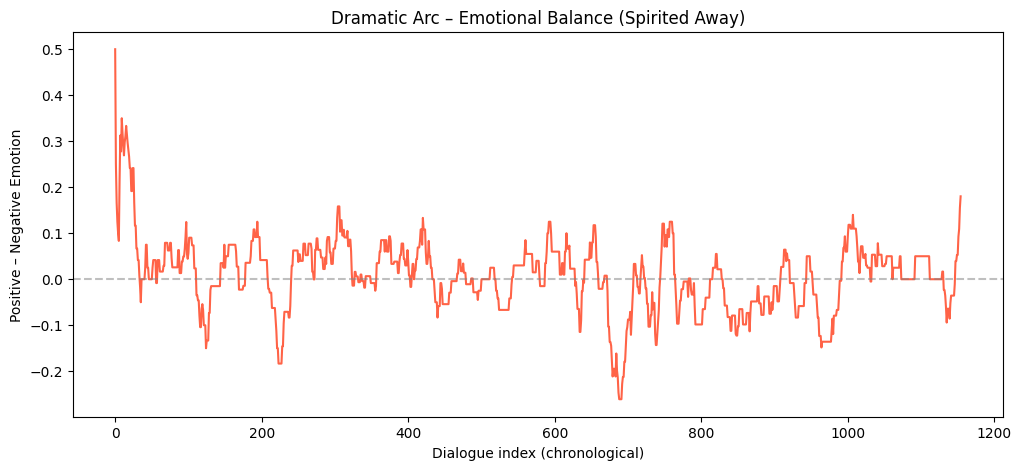

In [92]:
import matplotlib.pyplot as plt

df_emotions["smooth_balance"] = df_emotions["emotion_balance"].rolling(window=20, min_periods=1).mean()

plt.figure(figsize=(12,5))
plt.plot(df_emotions["smooth_balance"], color="tomato")
plt.title("Dramatic Arc – Emotional Balance (Spirited Away)")
plt.xlabel("Dialogue index (chronological)")
plt.ylabel("Positive – Negative Emotion")
plt.axhline(0, color="grey", linestyle="--", alpha=0.5)
plt.show()


In [94]:
#save it
# df_emotions[df_emotions['title']=='Spirited Away'].head()
df_emotions.to_csv('emotion_data.csv', index=False)

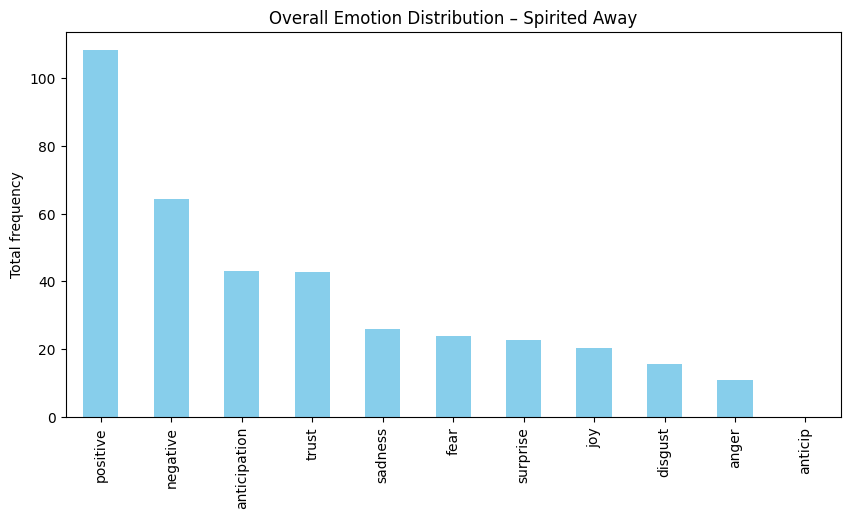

In [81]:
emotion_totals = df_emotions[emotion_df.columns].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))
emotion_totals.plot(kind="bar", color="skyblue")
plt.title("Overall Emotion Distribution – Spirited Away")
plt.ylabel("Total frequency")
plt.show()


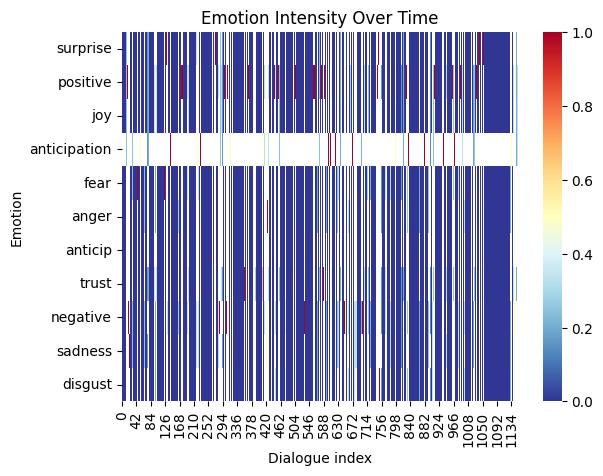

In [82]:
import seaborn as sns

sns.heatmap(df_emotions[emotion_df.columns].T, cmap="RdYlBu_r", cbar=True)
plt.title("Emotion Intensity Over Time")
plt.xlabel("Dialogue index")
plt.ylabel("Emotion")
plt.show()


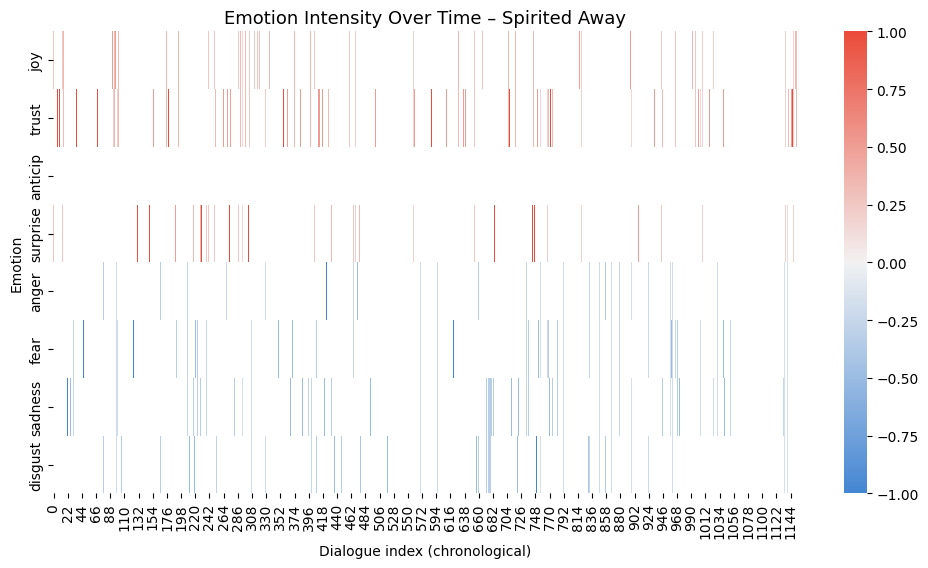

In [83]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# map emotions to positive (+1) or negative (-1)
emotion_polarity = {
    "joy": 1,
    "trust": 1,
    "anticip": 1,
    "surprise": 1,
    "anger": -1,
    "fear": -1,
    "sadness": -1,
    "disgust": -1
}

# apply polarity weighting
weighted = df_emotions[emotion_polarity.keys()].copy()
for emo, polarity in emotion_polarity.items():
    weighted[emo] = weighted[emo] * polarity

# replace 0s with np.nan so they show as white
weighted = weighted.replace(0, np.nan)

# build custom diverging palette:
# red (neg) → white (neutral) → blue (pos)
cmap = sns.diverging_palette(250, 15, s=80, l=55, as_cmap=True)

plt.figure(figsize=(12, 6))
sns.heatmap(
    weighted.T,
    cmap=cmap,
    cbar=True,
    center=0,        # makes white sit at 0
    linewidths=0,
    linecolor=None,
    square=False
)
plt.title("Emotion Intensity Over Time – Spirited Away", fontsize=13)
plt.xlabel("Dialogue index (chronological)")
plt.ylabel("Emotion")
plt.show()
